# Random Forest sur Ozone

## A. Pourquoi tester ce modèle ?

La forêt agrège des arbres ajustés sur des rééchantillonnages des dossiers, avec un sous-ensemble aléatoire de variables à chaque division. Elle représente des seuils et interactions RH, mais des feuilles très petites peuvent apprendre du bruit. La limitation de la complexité améliore-t-elle le classement de la forêt initiale ?


## B. Quelles données lui donne-t-on ?

Une ligne représente un dossier salarié Ozone. La classe positive est `Attrition = Yes`, soit un départ observé dans le fichier. Aucune date de mesure, date d’événement, cohorte datée ou information de site ne permet d’établir l’horizon ou de former une validation temporelle crédible.

La variante `data/variantes/01_baseline.xlsx` conserve 1 518 lignes et 31 colonnes de la source Ozone. La préparation historique écarte les constantes et l’identifiant EmployeeNumber. Le chargeur vérifie les modalités, l’absence de manquants et de valeurs numériques non finies. Les variantes simulées de suppression et de plafonnement sont écartées. Les valeurs atypiques sont conservées. Les doublons exacts sont contrôlés sur les dossiers et après retrait de la cible. Les index Excel servent uniquement à identifier une ligne et à départager les scores.

Les 30 champs du tableau sont les mêmes pour tous les modèles. Un scénario de scoring supposerait un instantané RH avant tout départ ou avis de départ, avec les caractéristiques individuelles et de poste, enquêtes, salaires, évaluations et compteurs d’ancienneté déjà connus à cet instant. Aucun champ de sortie explicite ne figure dans ce périmètre. Le fichier ne date pas ses mesures. La disponibilité réelle des champs sensibles au temps, notamment l’ancienneté, les évaluations et les hausses salariales, reste à vérifier avant tout usage prospectif.

On reproduit le split stratifié 80/20 et les cinq plis historiques, graine 42, identité vérifiée avec les journaux 04 et 05 et les empreintes de la source. Le test a déjà servi aux comparaisons 04, 05 et 06. Les scores ci-dessous sont rétrospectifs.


- **binaire** — Gender, OverTime
- **nominale** — BusinessTravel, Department, EducationField, JobRole, MaritalStatus
- **score_ordonne** — Education, EnvironmentSatisfaction, JobInvolvement, JobLevel, JobSatisfaction, PerformanceRating, RelationshipSatisfaction, StockOptionLevel, WorkLifeBalance
- **quantitative** — Age, DailyRate, DistanceFromHome, HourlyRate, MonthlyIncome, MonthlyRate, NumCompaniesWorked, PercentSalaryHike, TotalWorkingYears, TrainingTimesLastYear, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager

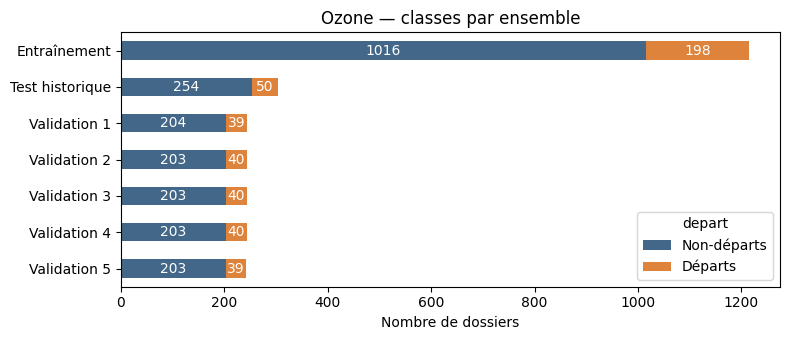

{'Python': '3.9.6',
 'pandas': '2.3.3',
 'numpy': '2.0.2',
 'scikit-learn': '1.6.1',
 'matplotlib': '3.9.4',
 'openpyxl': '3.1.5',
 'nbclient': '0.10.2'}

In [1]:
from pathlib import Path
import sys

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'attrition_comparison.py').is_file())
sys.path.insert(0, str(root))

import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from threadpoolctl import threadpool_limits

from src.modeling import BINARY, NOMINAL, SCORES, build_pipelines
from src.attrition_comparison import (
    evaluate_config, fit_search, load_comparison, plot_counts, plot_search,
    plot_test, validation_table, versions,
)

train, test, y_train, y_test, folds, groups, quantitative = load_comparison()
fields = groups.groupby('groupe', sort=False).variable.agg(', '.join)
display(Markdown('\n'.join(f'- **{group}** — {columns}' for group, columns in fields.items())))
plot_counts(y_train, y_test, folds)
display(versions(None))


Les 1 214 dossiers d’entraînement comptent 198 départs (16,31 %), et le test en compte 50 sur 304 (16,45 %). Chaque pli contient environ 40 départs. Les contrôles ne relèvent aucun doublon exact. Sans identifiant métier dans la variante, un doublon partiel entre dossiers ne peut être exclu par rapprochement d’identifiants.

## C. Comment entraîne-t-on la configuration de départ ?

On reprend le prétraitement 05. Catégories en indicatrices, deux binaires encodées et scores ordonnés numériques. La forêt initiale a 200 arbres, une profondeur libre, des feuilles d’au moins un dossier et √p colonnes transformées candidates.

Les transformations apprises sont ajustées par le pipeline dans chaque pli. Le fichier contrôlé est complet, donc aucune imputation n’est requise. Toutes les variables du périmètre sont conservées.

In [2]:
references = build_pipelines(quantitative)
method = 'predict_proba'
pipeline = references['RandomForest']
configs = [{}, {'min_samples_leaf': 2}] + [
    dict(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf, max_features=features)
    for trees, depth in [(100, 6), (300, None)]
    for leaf in (2, 8) for features in ('sqrt', .5)
]
display(pipeline.named_steps['modele'])

RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=42)

L’objet affiché fixe le modèle de départ. À chaque ajustement, les dossiers bruts passent par sa préparation, puis par l’estimateur. En validation et en test, l’estimateur transforme les dossiers en scores à partir des paramètres déjà appris.

## D. Comment règle-t-on les hyperparamètres ?

100 et 300 arbres encadrent les 200 de départ et font varier le coût et le lissage de l’agrégation. Une profondeur 6 borne les interactions, tandis que None laisse croître les arbres. Des feuilles de taille 2 ou 8 évitent les estimations sur des dossiers isolés. √p et 50 % modulent la diversité des arbres. Le plan couple profondeur et nombre d’arbres pour limiter le budget. Il permet de comparer les couples, avec des comparaisons de taille de feuille et de sous-échantillonnage à l’intérieur de chaque couple.

L’AP moyenne sur les cinq plis privilégie la qualité du classement de la classe minoritaire. On départage les égalités exactes par l’ordre déclaré (départ d’abord), et on limite la recherche à une petite grille sur un seul thread. La dispersion du graphique est descriptive, les plis ne sont pas indépendants.

10 configurations × 5 plis = 50 ajustements


,AP CV,Écart-type AP,ROC-AUC CV,Secondes / pli,Paramètres
7,0.5690,0.1156,0.8030,1.4069,"{'max_depth': None, 'max_features': 0.5, 'min_..."
6,0.5687,0.1008,0.8031,0.7349,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
0,0.5633,0.1029,0.8056,0.5667,{}
1,0.5587,0.1004,0.7995,0.4944,{'min_samples_leaf': 2}
8,0.5502,0.1148,0.8011,0.6938,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
3,0.5470,0.1232,0.7996,0.3884,"{'max_depth': 6, 'max_features': 0.5, 'min_sam..."
4,0.5433,0.1307,0.8035,0.2117,"{'max_depth': 6, 'max_features': 'sqrt', 'min_..."
9,0.5404,0.1327,0.7947,1.3874,"{'max_depth': None, 'max_features': 0.5, 'min_..."
2,0.5395,0.1143,0.7918,0.2229,"{'max_depth': 6, 'max_features': 'sqrt', 'min_..."
5,0.5373,0.1299,0.7882,0.3305,"{'max_depth': 6, 'max_features': 0.5, 'min_sam..."


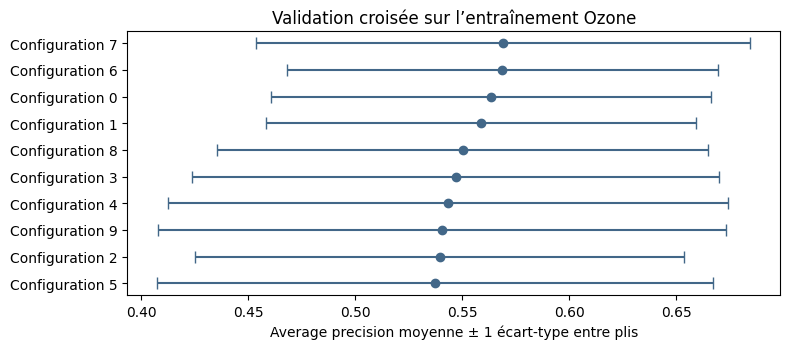

La configuration **7** arrive en tête avec une AP moyenne de **0.569**, écart-type 0.116.

In [3]:
print(f'{len(configs)} configurations × {len(folds)} plis = {len(configs)*len(folds)} ajustements')
with threadpool_limits(limits=1):
    search = fit_search(pipeline, configs, train, y_train, folds)
ranking = validation_table(search)
best = ranking.index[0]
display(ranking.round(4))
plot_search(search)
winner = ranking.iloc[0]
display(Markdown(f"La configuration **{best}** arrive en tête avec une AP moyenne de **{winner['AP CV']:.3f}**, écart-type {winner['Écart-type AP']:.3f}."))


Les lignes du tableau et les points du graphique correspondent aux mêmes configurations. Les écarts entre moyennes sont à lire au regard de leur dispersion. La meilleure moyenne après recherche peut surestimer la performance future.

Le candidat **7** est retenu. L’AP moyenne passe de 0.5633 à 0.5690.

## E. Que donnent les résultats sur de nouveaux dossiers ?

Pour chaque configuration fixée, on calcule un score par dossier d’entraînement hors de son pli d’ajustement, puis on maximise le F1 sur ces scores. Cet objectif donne le même poids à la précision et au rappel via leur moyenne harmonique, faute de coût métier défini. En cas d’égalité, on retient le seuil le plus haut. La validation du seuil et le réglage partagent les plis, ce qui rend leurs chiffres optimistes lorsqu’ils servent à juger le modèle sélectionné. Le seuil est appliqué après réajustement sur l’entraînement complet.

Les courbes et métriques de classement reposent sur des scores continus. Les sorties de probabilité sont utilisées comme scores de classement sans interprétation en risque individuel, faute de validation de calibration. À capacité commune, on prend l’arrondi supérieur de 10 % du test, avec ex æquo départagés par l’index source croissant. Ce volume est une convention. La matrice de confusion illustre la configuration réglée.

La baseline prédit toujours le non-départ et signale zéro dossier. Son score continu constant donne une ROC-AUC de 0,5 et une AP égale à la prévalence. Les gains ajoutent un repère de classement aléatoire à volume égal.


,Départ (configuration initiale),Réglage
Indicateur,,
AP CV,0.5633,0.5690
ROC-AUC CV,0.8056,0.8030
AP test,0.4886,0.4980
ROC-AUC test,0.8072,0.8112
Seuil,0.2750,0.3256
Précision,0.4231,0.5000
Rappel,0.4400,0.5200
F1,0.4314,0.5098
Alertes au seuil,52.0000,52.0000


,Baseline majoritaire — test
Exactitude,0.8355
AP,0.1645
ROC-AUC,0.5000
Précision,0.0000
Rappel,0.0000
F1,0.0000
Alertes,0.0000
Départs retrouvés,0.0000


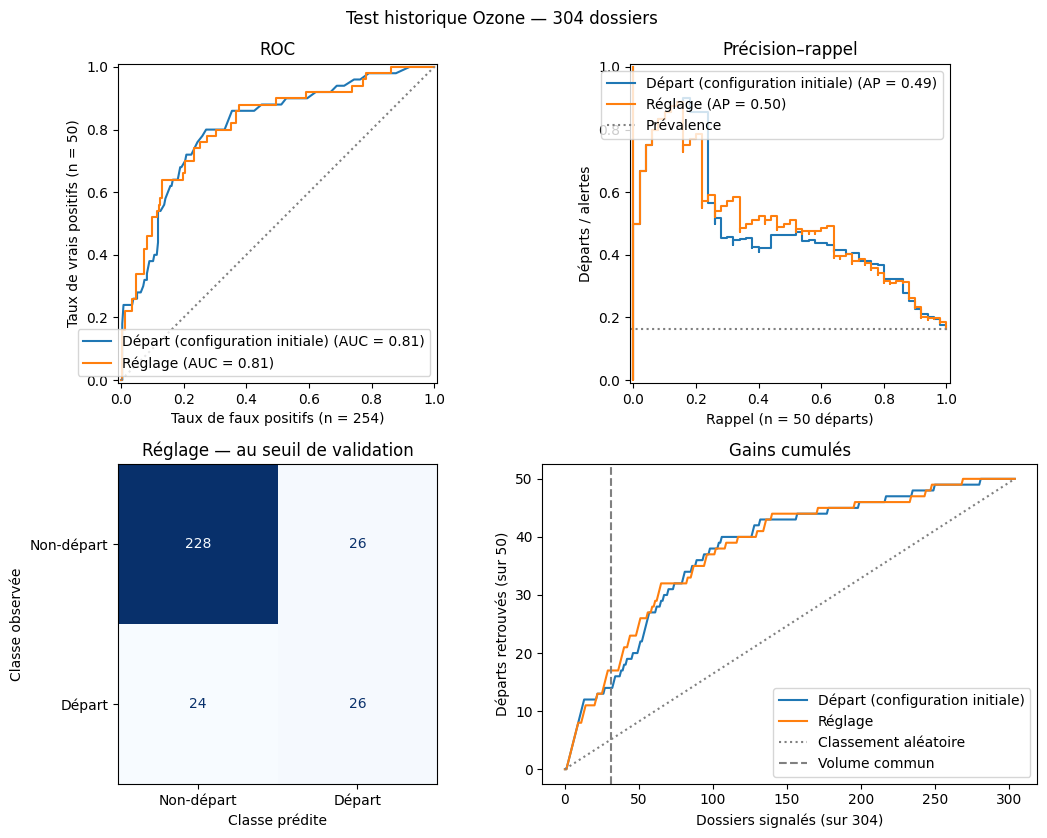

In [4]:
labels = ['Départ (configuration initiale)', 'Réglage']
params = [search.cv_results_['params'][i] for i in [0, best]]
models = [clone(pipeline).set_params(**p) for p in params]
rows, scores = {}, {}
with threadpool_limits(limits=1):
    for label, model, i in zip(labels, models, [0, best]):
        row, scores[label] = evaluate_config(model, train, y_train, folds, test, y_test, method)
        rows[label] = {'AP CV': search.cv_results_['mean_test_AP'][i],
                       'ROC-AUC CV': search.cv_results_['mean_test_AUC'][i], **row}
fitted = models[-1]
comparison = pd.DataFrame(rows).T
display(comparison.T.round(4).rename_axis('Indicateur'))

majority = pd.Series({'Exactitude': 1 - y_test.mean(), 'AP': y_test.mean(), 'ROC-AUC': .5,
                      'Précision': 0, 'Rappel': 0, 'F1': 0, 'Alertes': 0, 'Départs retrouvés': 0})
display(majority.round(4).to_frame('Baseline majoritaire — test'))
result = rows['Réglage']
plot_test(y_test, scores, result['Seuil'])


La courbe précision–rappel se lit par rapport à la part des départs observés. Les gains cumulés donnent directement le nombre de départs retrouvés pour un nombre de dossiers à traiter. La matrice utilise le seuil F1 appris sur l’entraînement. La ligne à 31 dossiers correspond à la convention de capacité, qui peut donner un volume différent de celui du seuil F1.

La forêt retenue comporte 300 arbres, une profondeur libre, deux dossiers minimum par feuille et 50 % des colonnes transformées candidates par division. Face au départ elle retrouve trois départs supplémentaires parmi les 31 alertes. Son AP test (0,498) reste légèrement inférieure à celle de la forêt 05 archivée (0,507) sur les mêmes dossiers.

## F. Qu’est-ce que le modèle apprend sur Ozone ?

Une permutation mélange une colonne source sur le test historique, avant le prétraitement, et mesure la perte d’AP. On répète 20 fois avec une graine fixe. La dispersion est celle des permutations sur ce test. Une variable corrélée peut être remplacée par ses voisines, ou la permutation peut créer des combinaisons rares.

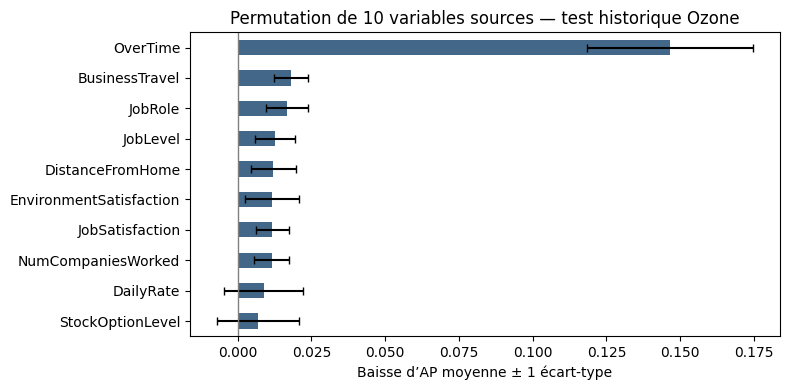

La plus forte baisse moyenne mesurée concerne **OverTime** (+0.147 d’AP). Les barres décrivent la dépendance du classement aux colonnes de ce fichier.

In [5]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

with threadpool_limits(limits=1):
    permutation = permutation_importance(fitted, test, y_test, scoring='average_precision',
                                         n_repeats=20, random_state=42, n_jobs=1)
importance = pd.DataFrame({'Baisse AP': permutation.importances_mean,
                           'Écart-type': permutation.importances_std}, index=test.columns)
leaders = importance.nlargest(10, 'Baisse AP').sort_values('Baisse AP')
ax = leaders['Baisse AP'].plot.barh(xerr=leaders['Écart-type'], figsize=(8, 4),
                                  color='#426788', capsize=3)
ax.axvline(0, color='gray', lw=1)
ax.set(xlabel='Baisse d’AP moyenne ± 1 écart-type',
       title='Permutation de 10 variables sources — test historique Ozone')
plt.tight_layout()
plt.show()

display(Markdown(f"La plus forte baisse moyenne mesurée concerne **{leaders.index[-1]}** "
f"({leaders.iloc[-1]['Baisse AP']:+.3f} d’AP). Les barres décrivent la dépendance du classement aux colonnes de ce fichier." ))

Plusieurs mesures d’ancienneté ou de rémunération peuvent porter une information commune. Un effet faible isolément peut refléter cette redondance, et un effet élevé peut refléter une association indirecte. La qualité du classement se mesure par l’AP et la ROC-AUC. L’analyse des variables décrit des associations conditionnelles. Elle ne mesure pas l’effet d’une intervention RH.

## G. Conclusion du notebook

La conclusion reprend les résultats calculés sur le test historique pour le seuil F1 et le volume commun.

In [6]:
initial = rows[labels[0]]
display(Markdown(
    f"Le modèle réglé atteint une **AP de {result['AP test']:.3f}** et une "
    f"**ROC-AUC de {result['ROC-AUC test']:.3f}** au test. Le réglage change l’AP "
    f"de {result['AP CV'] - initial['AP CV']:+.3f} en validation et de "
    f"{result['AP test'] - initial['AP test']:+.3f} au test. "
    f"Le nombre de départs retrouvés à volume fixe passe de {initial['Départs à 10 %']} "
    f"à {result['Départs à 10 %']}.\n\n"
    f"Au seuil F1, sur {result['Alertes au seuil']} dossiers signalés, "
    f"{result['Départs au seuil']} départs observés sont retrouvés, sur {int(y_test.sum())} "
    f"départs au total. Au volume commun, sur **{result['Alertes à 10 %']} dossiers signalés**, "
    f"**{result['Départs à 10 %']} départs** sont retrouvés sur {int(y_test.sum())}.\n\n"
    "Pour Ozone, ce modèle serait à retenir si ses interactions améliorent le rendement à volume fixé et se reproduisent en validation prospective. "
    "Une cohorte future, des salariés ou sites différents peuvent présenter des caractéristiques "
    "et une prévalence différentes. Le fichier ne permet pas d’établir ces transferts."
))

Le modèle réglé atteint une **AP de 0.498** et une **ROC-AUC de 0.811** au test. Le réglage change l’AP de +0.006 en validation et de +0.009 au test. Le nombre de départs retrouvés à volume fixe passe de 14 à 17.

Au seuil F1, sur 52 dossiers signalés, 26 départs observés sont retrouvés, sur 50 départs au total. Au volume commun, sur **31 dossiers signalés**, **17 départs** sont retrouvés sur 50.

Pour Ozone, ce modèle serait à retenir si ses interactions améliorent le rendement à volume fixé et se reproduisent en validation prospective. Une cohorte future, des salariés ou sites différents peuvent présenter des caractéristiques et une prévalence différentes. Le fichier ne permet pas d’établir ces transferts.

Cette lecture dépend de la capacité d’intervention. Pour un nombre d’alertes fixé, privilégier le décompte à volume commun. La synthèse rapproche ce décompte du classement global et de l’incertitude des écarts.